# Module 1: Markets, prices and returns

Everything later in the project works with **returns**, not prices. This notebook builds
the data layer (`statarb.data`) and the return toolkit (`statarb.returns`), and uses them
to look at real prices: what a daily bar contains, why adjusted prices exist, how simple
and log returns differ, how volatility scales with time, and how far real returns are from
Gaussian.

Lecture notes, glossary and interview questions: [`lecture.md`](lecture.md).

**Contents**
1. Download and inspect daily bars
2. Corporate actions: splits, dividends and the adjusted close
3. Simple vs log returns
4. Volatility, the square-root-of-time rule, and fat tails
5. Co-movement: correlations and beta
6. Exercises

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from statarb import data, returns
from statarb.config import TRADING_DAYS

pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

START, END = "2010-01-01", "2024-12-31"  # 15 calendar years

## 1. Download and inspect daily bars

The universe for this module, chosen to have a little of everything:

| Ticker | What it is |
|---|---|
| SPY | ETF tracking the S&P 500 index: "the market" |
| XLE, XLP | Sector ETFs: US energy, US consumer staples |
| AAPL, MSFT | Large technology companies |
| JPM | A large bank |
| XOM, CVX | Oil majors (both in XLE) |
| KO, PEP | Coca-Cola and PepsiCo (both in XLP), the textbook pair |

`load_bars` returns one ticker's full daily bar. Let's look at Apple around its 4-for-1
stock split on 31 August 2020.

In [2]:
TICKERS = ["SPY", "XLE", "XLP", "AAPL", "MSFT", "JPM", "XOM", "CVX", "KO", "PEP"]

aapl = data.load_bars("AAPL", START, END)
aapl.loc["2020-08-26":"2020-09-03"]

,open,high,low,close,adj_close,volume,dividends,splits
date,,,,,,,,
2020-08-26,126.1800,126.9925,125.0825,126.5225,122.6178,1.6302e+08,0.0,0.0
2020-08-27,127.1425,127.4850,123.8325,125.0100,121.1519,1.5555e+08,0.0,0.0
2020-08-28,126.0125,126.4425,124.5775,124.8075,120.9557,1.8763e+08,0.0,0.0
2020-08-31,127.5800,131.0000,126.0000,129.0400,125.0575,2.2570e+08,0.0,4.0
2020-09-01,132.7600,134.8000,130.5300,134.1800,130.0389,1.5195e+08,0.0,0.0
2020-09-02,137.5900,137.9800,127.0000,131.4000,127.3447,2.0012e+08,0.0,0.0
2020-09-03,126.9100,128.8400,120.5000,120.8800,117.1494,2.5760e+08,0.0,0.0


Each row is one **bar** for one trading day:

- `open`, `high`, `low`, `close`: first, highest, lowest and last traded price of the day
  (together, **OHLC**). `volume` is the number of shares traded.
- `dividends`: cash paid per share, recorded on the **ex-dividend date** (the first day a
  buyer no longer receives the upcoming dividend).
- `splits`: the split ratio on the day a split takes effect (4.0 here).
- `adj_close`: the close **adjusted** for splits and dividends, so that its day-to-day
  ratio is the investor's true return.

Note something surprising: the `close` before 31 August is about 125, not about 500. On the
day Apple actually traded at around 500 per share. **Yahoo's `close` is already
split-adjusted** (but not dividend-adjusted). We come back to this in Section 2.

A first sanity check: by definition `low <= open, close <= high` on every bar.

In [3]:
ok = (aapl["low"] <= aapl[["open", "close"]].min(axis=1)) & (
    aapl[["open", "close"]].max(axis=1) <= aapl["high"]
)
print(f"bars passing the OHLC consistency check: {ok.mean():.2%} of {len(aapl)}")

bars passing the OHLC consistency check: 100.00% of 3774


Now the whole universe. `load_prices` returns one field (by default `adj_close`) as a wide
table: dates down, tickers across. The second call reads the parquet cache, and the cache
records when it was downloaded.

In [4]:
prices = data.load_prices(TICKERS, START, END)
print(prices.shape)
print("cache:", data.cache_info("SPY"))
prices.tail()

(3774, 10)
cache: {'ticker': 'SPY', 'start': '2010-01-01', 'end': '2024-12-31', 'downloaded_at': '2026-11-12T17:03:58+00:00', 'source': 'yahoo_download', 'auto_adjust': False}


ticker,SPY,XLE,XLP,AAPL,MSFT,JPM,XOM,CVX,KO,PEP
date,,,,,,,,,,
2024-12-24,589.7147,40.1563,75.8661,256.3398,433.3635,232.8032,100.6148,133.7330,59.8761,142.5974
2024-12-26,589.7539,40.1231,76.1049,257.1538,432.1601,233.6006,100.6999,133.8632,59.6189,142.2521
2024-12-27,583.5459,40.1183,75.7324,253.7485,424.6831,231.7079,100.6905,133.8818,59.5045,142.6720
2024-12-30,576.8868,40.1136,74.8443,250.3830,419.0605,229.9305,100.0096,133.0171,59.1043,141.5802
2024-12-31,574.7881,40.6402,75.0735,248.6158,415.7757,230.3052,101.7212,134.6628,59.3235,141.8975


## 2. Corporate actions: splits, dividends and the adjusted close

### 2a. A stock split

In a 4-for-1 split each share becomes four shares, each worth a quarter as much. Nothing
economic happens; the shareholder's wealth is unchanged. But the *traded* price drops by 75%
overnight.

To see the as-traded price we undo Yahoo's split adjustment with
`data.unadjust_splits`. It needs every split up to the download date, because the provider
adjusts all history for all splits since, so we fetch the full split record.

AAPL splits since 2010:
 date
2014-06-09    7.0
2020-08-31    4.0
Name: splits, dtype: float64
return on 2020-08-31 from as-traded prices: -74.2%
return on 2020-08-31 from adjusted prices:  +3.4%


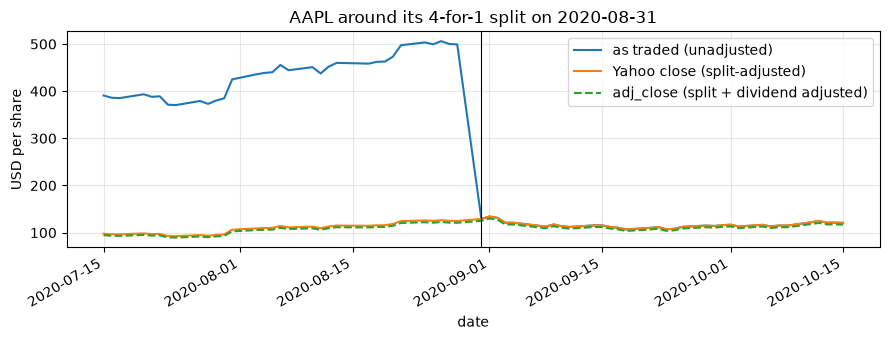

In [5]:
all_splits = data.load_bars("AAPL", START, pd.Timestamp.today().normalize())["splits"]
print("AAPL splits since 2010:\n", all_splits[all_splits > 0])

as_traded = data.unadjust_splits(aapl["close"], all_splits)
window = slice("2020-07-15", "2020-10-15")

fig, ax = plt.subplots(figsize=(9, 3.5))
as_traded[window].plot(ax=ax, label="as traded (unadjusted)")
aapl["close"][window].plot(ax=ax, label="Yahoo close (split-adjusted)")
aapl["adj_close"][window].plot(ax=ax, label="adj_close (split + dividend adjusted)", ls="--")
ax.axvline(pd.Timestamp("2020-08-31"), color="k", lw=0.8)
ax.set_title("AAPL around its 4-for-1 split on 2020-08-31")
ax.set_ylabel("USD per share")
ax.legend()
fig.tight_layout()

naive = returns.simple_returns(as_traded)["2020-08-31"]
true = returns.simple_returns(aapl["adj_close"])["2020-08-31"]
print(f"return on 2020-08-31 from as-traded prices: {naive:+.1%}")
print(f"return on 2020-08-31 from adjusted prices:  {true:+.1%}")

A backtest on unadjusted prices would book a three-quarters "crash" that never happened
(or, for a short position, a fantastic fake profit). Splits are easy to spot; the subtler
problem is dividends.

### 2b. A dividend

On the ex-dividend date the price falls by roughly the dividend, because a buyer that day
no longer receives it. The holder did not lose money: the drop is paid back in cash. The
raw `close` sees only the drop; `adj_close` scales all earlier prices down by the factor
$1 - D/P_{t-1}$ so that the ratio across the ex-date reflects the total return.

Coca-Cola pays a dividend every quarter:

In [6]:
ko = data.load_bars("KO", START, END)
ex_dates = ko.index[ko["dividends"] > 0]
print(f"KO ex-dividend dates in sample: {len(ex_dates)}; last few:", list(ex_dates[-4:].date))

ex = ex_dates[ex_dates.year == 2023][0]
around = ko.loc[
    ex - pd.Timedelta(days=4) : ex + pd.Timedelta(days=2), ["close", "adj_close", "dividends"]
]
around

KO ex-dividend dates in sample: 60; last few: [datetime.date(2024, 3, 14), datetime.date(2024, 6, 14), datetime.date(2024, 9, 13), datetime.date(2024, 11, 29)]


,close,adj_close,dividends
date,,,
2023-03-13,59.81,53.6088,0.00
2023-03-14,60.03,53.8060,0.00
2023-03-15,60.43,54.1645,0.00
2023-03-16,60.30,54.4625,0.46
2023-03-17,60.02,54.2096,0.00


In [7]:
R_close = returns.simple_returns(ko["close"])[ex]
R_adj = returns.simple_returns(ko["adj_close"])[ex]
D_over_P = ko.loc[ex, "dividends"] / ko["close"].shift(1)[ex]
print(f"ex-date {ex.date()}: return from close {R_close:+.3%}, from adj_close {R_adj:+.3%}")
print(f"difference {R_adj - R_close:.3%}  vs  dividend / previous close {D_over_P:.3%}")

ex-date 2023-03-16: return from close -0.215%, from adj_close +0.550%
difference 0.765%  vs  dividend / previous close 0.761%


One dividend is a fraction of a percent, but they compound. Compare the growth over the
full sample of the **price return** (raw `close`) with the **total return** (`adj_close`).
The last column, $1 - \text{price return}/\text{total return}$, is the share of the total
return that came from dividends.

In [8]:
close_prices = data.load_prices(TICKERS, START, END, field="close")
growth = pd.DataFrame(
    {
        "price return (close)": close_prices.iloc[-1] / close_prices.iloc[0] - 1,
        "total return (adj_close)": prices.iloc[-1] / prices.iloc[0] - 1,
    }
)
growth["dividends' share"] = 1 - growth.iloc[:, 0] / growth.iloc[:, 1]
growth.style.format("{:.0%}")

,price return (close),total return (adj_close),dividends' share
ticker,,,
SPY,417%,581%,28%
XLE,46%,138%,67%
XLP,195%,341%,43%
AAPL,3176%,3784%,16%
MSFT,1262%,1709%,26%
JPM,459%,722%,36%
XOM,56%,174%,68%
CVX,83%,232%,64%
KO,118%,247%,52%


For high-dividend names dividends are about half (KO, PEP, XLP) to two-thirds (XOM, CVX,
XLE) of the 15-year return. For stat arb this matters more than it looks: a long KO / short PEP
position receives KO's dividends and *pays* PEP's (the short seller owes the lender any
dividend). Raw closes get the P&L of every such pair wrong around every ex-date.

**Rule for the rest of the project: compute returns from `adj_close`.**

## 3. Simple vs log returns

$$R_t = \frac{P_t}{P_{t-1}} - 1, \qquad r_t = \ln\frac{P_t}{P_{t-1}} = \ln(1 + R_t).$$

Taylor-expanding, $r = R - R^2/2 + R^3/3 - \dots$, so the two agree to first order and
$r < R$ always (for $R \neq 0$).

In [9]:
R = returns.simple_returns(prices)
r = returns.log_returns(prices)

spy = pd.DataFrame({"R": R["SPY"], "r": r["SPY"]})
spy["R - r"] = spy["R"] - spy["r"]
spy["R^2 / 2"] = spy["R"] ** 2 / 2
# one day closest to each typical move size, then the three largest moves
picks = [(spy["R"].abs() - size).abs().idxmin() for size in (0.001, 0.005, 0.01, 0.02)]
picks += list(spy["R"].abs().nlargest(3).index)
spy.loc[picks]

,R,r,R - r,R^2 / 2
date,,,,
2017-09-19,0.0010,0.0010,5.0079e-07,5.0112e-07
2013-11-22,0.0050,0.0050,1.2472e-05,1.2513e-05
2022-04-06,-0.0100,-0.0100,5.0331e-05,4.9995e-05
2022-05-26,0.0200,0.0198,1.9701e-04,1.9963e-04
2020-03-16,-0.1094,-0.1159,6.4628e-03,5.9868e-03
2020-03-12,-0.0957,-0.1006,4.8917e-03,4.5771e-03
2020-03-24,0.0906,0.0867,3.8723e-03,4.1045e-03


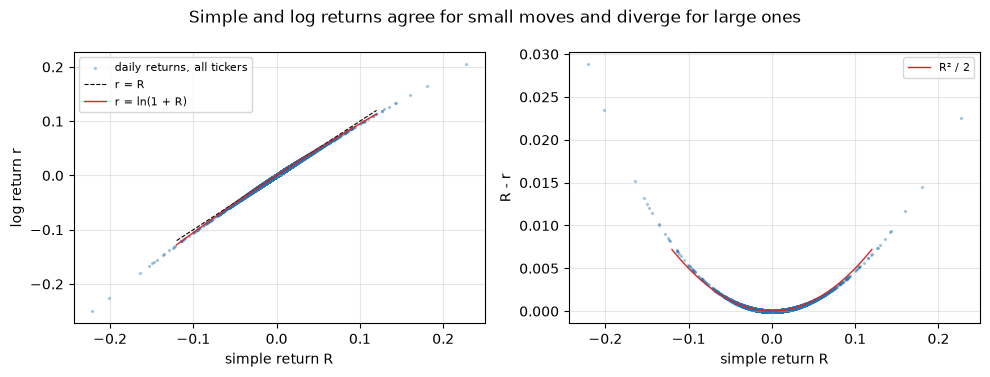

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
x = np.linspace(-0.12, 0.12, 200)
R_all, r_all = R.to_numpy().ravel(), r.to_numpy().ravel()
axes[0].scatter(R_all, r_all, s=2, alpha=0.3, label="daily returns, all tickers")
axes[0].plot(x, x, "k--", lw=0.8, label="r = R")
axes[0].plot(x, np.log1p(x), "C3", lw=1, label="r = ln(1 + R)")
axes[0].set_xlabel("simple return R")
axes[0].set_ylabel("log return r")
axes[0].legend(fontsize=8)
axes[1].scatter(R_all, R_all - r_all, s=2, alpha=0.3)
axes[1].plot(x, x**2 / 2, "C3", lw=1, label="R² / 2")
axes[1].set_xlabel("simple return R")
axes[1].set_ylabel("R - r")
axes[1].legend(fontsize=8)
fig.suptitle("Simple and log returns agree for small moves and diverge for large ones")
fig.tight_layout()

On a typical 1% day the gap is $R^2/2 = 5 \times 10^{-5}$, i.e. half a basis point. On the
largest days of March 2020 it reaches 40–65 bp.

**Which to use when.** Log returns add over *time*; simple returns add across *assets*:

$$\ln\frac{P_T}{P_0} = \sum_{t=1}^{T} r_t, \qquad R^{\text{portfolio}}_t = \sum_i w_i R_{i,t}.$$

Check both on the data. First, time aggregation for SPY:

In [11]:
print(f"sum of SPY daily log returns: {r['SPY'].sum():.6f}")
print(f"ln(P_end / P_start):          {np.log(prices['SPY'].iloc[-1] / prices['SPY'].iloc[0]):.6f}")

sum of SPY daily log returns: 1.918802
ln(P_end / P_start):          1.918802


Second, portfolio aggregation. A portfolio holding half its money in KO and half in PEP
(rebalanced daily to 50/50) earns the weighted average of the two *simple* returns. Doing
the same with log returns is only an approximation:

In [12]:
w = pd.Series({"KO": 0.5, "PEP": 0.5})
port_R = R[w.index] @ w  # exact
port_r_wrong = r[w.index] @ w  # weighted log returns
error_bp = (returns.simple_to_log(port_R) - port_r_wrong) * 1e4
print("error from averaging log returns, in bp:")
print(
    f"  median {error_bp.abs().median():.3f}, max {error_bp.abs().max():.1f}, min {error_bp.min():.4f}"
)

error from averaging log returns, in bp:
  median 0.019, max 8.0, min 0.0000


Small per day, but systematic: the error is always of the same sign (Jensen's inequality,
since $\ln$ is concave), so it accumulates.

## 4. Volatility, the square-root-of-time rule, and fat tails

### 4a. Summary statistics

`returns.summary` reports annualised mean and volatility, skewness and excess kurtosis.
(Excess kurtosis is 0 for a Gaussian.)

In [13]:
returns.summary(r).sort_values("ann_vol")

,ann_mean,ann_vol,skew,excess_kurtosis,min,max,n_obs
ticker,,,,,,,
XLP,0.0991,0.1372,-0.5028,14.1698,-0.0987,0.0817,3773
KO,0.0831,0.1708,-0.7806,9.6293,-0.1017,0.0628,3773
SPY,0.1282,0.1710,-0.7215,11.5445,-0.1159,0.0867,3773
PEP,0.0901,0.1723,-0.5125,20.4991,-0.1214,0.1217,3773
XOM,0.0673,0.2497,-0.1619,7.3046,-0.1304,0.1194,3773
MSFT,0.1934,0.2558,-0.2101,8.0253,-0.1595,0.1329,3773
CVX,0.0802,0.2691,-0.9041,26.8646,-0.2501,0.2049,3773
XLE,0.0580,0.2758,-0.7977,15.5043,-0.2249,0.1487,3773
JPM,0.1407,0.2774,-0.0761,9.6836,-0.1621,0.1656,3773


Things to notice:

- Annualised volatility ranges from about 14–17% (XLP, KO, SPY, PEP) to about 28% (XLE,
  JPM, AAPL).
- Diversification helps only if the holdings differ: XLP is calmer than KO or PEP, but XLE
  is *not* calmer than XOM or CVX, because all its holdings share the same oil-price risk.
- The excess kurtosis is large for every asset (5 to 27). A Gaussian would give 0.
- Skewness is negative for every asset: the big down days are bigger than the big up days.

### 4b. Volatility changes over time

Volatility is not a constant of nature. Rolling estimates over a month (21 trading days)
and a quarter (63) show quiet regimes and violent bursts:

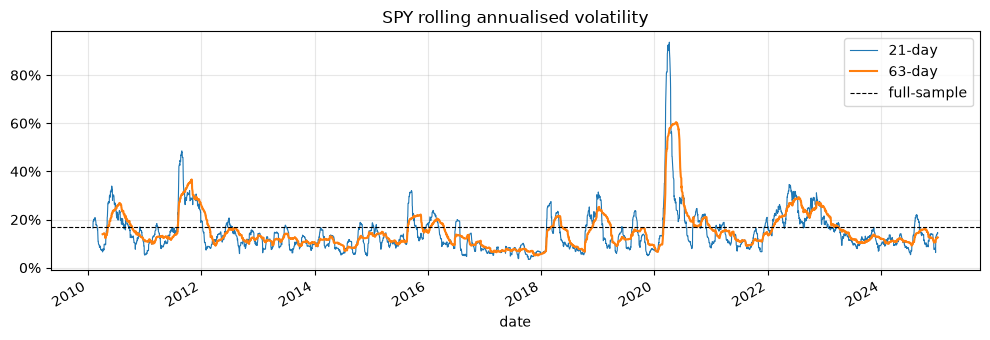

In [14]:
fig, ax = plt.subplots(figsize=(10, 3.5))
returns.rolling_volatility(r["SPY"], 21).plot(ax=ax, lw=0.8, label="21-day")
returns.rolling_volatility(r["SPY"], 63).plot(ax=ax, lw=1.5, label="63-day")
ax.axhline(r["SPY"].std() * np.sqrt(TRADING_DAYS), color="k", ls="--", lw=0.8, label="full-sample")
ax.set_title("SPY rolling annualised volatility")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend()
fig.tight_layout()

Volatility spends long stretches near 10–15% and then jumps: May 2010 (the "flash
crash"), August–October 2011 (US credit downgrade), August 2015, December 2018, March–April
2020 (COVID, above 90%) and 2022. Turbulent days cluster together. This **volatility
clustering** returns in Module 3.

### 4c. Does volatility scale like $\sqrt{T}$?

If daily returns are uncorrelated, the variance of a $T$-day return is $T$ times the daily
variance, exactly as in diffusion where $\langle x^2 \rangle = 2Dt$. Then annualising
daily, weekly or monthly volatility should give the same number. Test it with
non-overlapping 5-day and 21-day log returns (which are just sums of daily log returns):

In [15]:
def annualised_vol_from_horizon(log_ret: pd.DataFrame, horizon: int) -> pd.Series:
    blocks = np.arange(len(log_ret)) // horizon
    summed = log_ret.groupby(blocks).sum().iloc[:-1]  # drop the incomplete last block
    return summed.std() * np.sqrt(TRADING_DAYS / horizon)


scaling = pd.DataFrame({f"{h}-day": annualised_vol_from_horizon(r, h) for h in (1, 5, 21)})
scaling["ratio 21d / 1d"] = scaling["21-day"] / scaling["1-day"]
scaling

,1-day,5-day,21-day,ratio 21d / 1d
ticker,,,,
SPY,0.1710,0.1644,0.1361,0.7958
XLE,0.2758,0.2676,0.2728,0.9891
XLP,0.1373,0.1253,0.1096,0.7985
AAPL,0.2788,0.2745,0.2488,0.8923
MSFT,0.2558,0.2344,0.2100,0.8210
JPM,0.2774,0.2669,0.2606,0.9394
XOM,0.2497,0.2395,0.2485,0.9952
CVX,0.2691,0.2590,0.2393,0.8891
KO,0.1709,0.1668,0.1452,0.8496


The $\sqrt{T}$ rule is a first approximation, not a law. The columns are the same order of
magnitude, but for most assets the monthly-based figure is 10–25% *lower* than the
daily-based one. If returns are correlated from day to day, the variance of a sum picks up
covariance terms:

$$\operatorname{Var}\Big(\sum_{t=1}^{T} r_t\Big) = T\sigma^2\Big(1 + 2\sum_{k=1}^{T-1}\big(1 - \tfrac{k}{T}\big)\rho_k\Big),$$

where $\rho_k$ is the correlation between returns $k$ days apart. Negative $\rho_k$ (a big
down day tends to be followed by a partial rebound) makes long-horizon variance grow
*slower* than $T$. The lag-1 autocorrelation is indeed negative for every ticker here:

In [16]:
r.apply(lambda s: s.autocorr(lag=1)).to_frame("lag-1 autocorrelation").T

ticker,SPY,XLE,XLP,AAPL,MSFT,JPM,XOM,CVX,KO,PEP
lag-1 autocorrelation,-0.0985,-0.0276,-0.0956,-0.0385,-0.1034,-0.096,-0.0219,-0.0684,-0.0323,-0.1421


With only about 180 monthly observations each ratio has a standard error of 5% or more, so
don't over-read a single ratio; the consistent sign across assets is the more robust
signal. Comparing variances across horizons in this way is the **variance-ratio test**
(Lo and MacKinlay, 1988). For stat arb, the point is that annualised volatility depends on
the horizon you measure it at, and mean reversion is exactly what makes it fall.

### 4d. Fat tails

Standardise SPY's daily log returns to zero mean and unit variance and compare their
histogram with the standard Gaussian. The log scale on the y-axis makes the tails visible.

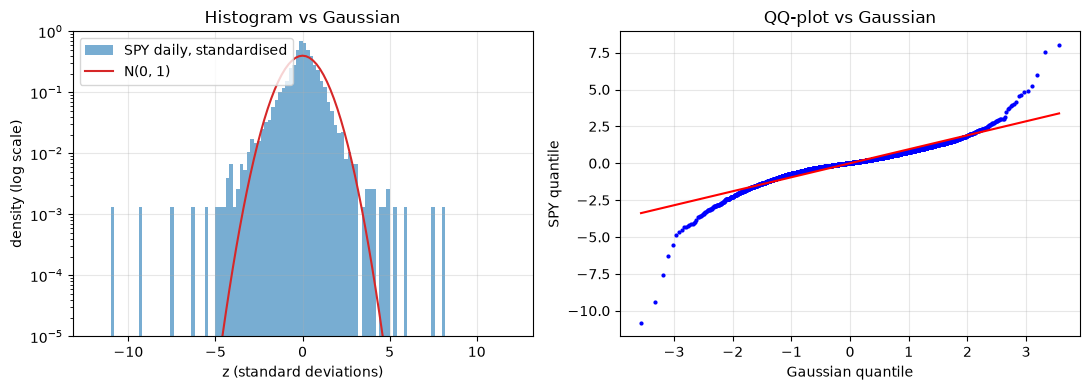

In [17]:
z = (r["SPY"] - r["SPY"].mean()) / r["SPY"].std()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
bins = np.linspace(-12, 12, 121)
axes[0].hist(z, bins=bins, density=True, alpha=0.6, label="SPY daily, standardised")
axes[0].plot(bins, stats.norm.pdf(bins), "C3", label="N(0, 1)")
axes[0].set_yscale("log")
axes[0].set_ylim(1e-5, 1)
axes[0].set_xlabel("z (standard deviations)")
axes[0].set_ylabel("density (log scale)")
axes[0].legend()
axes[0].set_title("Histogram vs Gaussian")

stats.probplot(z, dist="norm", plot=axes[1])
axes[1].get_lines()[0].set_markersize(2)
axes[1].set_title("QQ-plot vs Gaussian")
axes[1].set_xlabel("Gaussian quantile")
axes[1].set_ylabel("SPY quantile")
fig.tight_layout()

**Reading a QQ-plot.** Each point pairs a quantile of the data with the same quantile of
the Gaussian. A Gaussian sample lies on the straight line. Here the ends bend away: the
data's extreme quantiles are much further out than the Gaussian's. That is what **fat
tails** (excess kurtosis) look like. The histogram says the same thing: the centre is more
peaked and the tails far heavier than the red curve.

Why it matters for stat arb: a long/short book is hedged against *typical* market moves,
but on a 6- or 10-sigma day correlations change, hedges break, and losses that a Gaussian
model calls "once in the age of the universe" happen every few years.

## 5. Co-movement: correlations and beta

Stat arb exploits assets that move together. The correlation matrix of daily returns is a
first look:

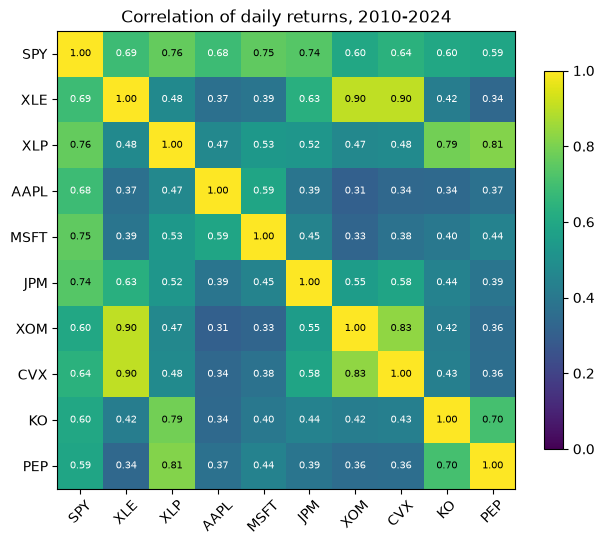

In [18]:
corr = R.corr()

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, vmin=0, vmax=1, cmap="viridis")
ax.set_xticks(range(len(corr)), corr.columns, rotation=45)
ax.set_yticks(range(len(corr)), corr.index)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        value = corr.iloc[i, j]
        colour = "k" if value > 0.7 else "w"
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=7, color=colour)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlation of daily returns, 2010-2024")
fig.tight_layout()

- Every correlation is positive: all stocks share a common **market** component.
- Blocks appear by sector: XOM, CVX and XLE correlate around 0.8–0.9; KO, PEP and XLP form
  another block. Those blocks are where pairs come from.

**Beta** measures each asset's sensitivity to the market: the slope of a regression of its
return on SPY's return, $\beta_i = \operatorname{Cov}(R_i, R_m) / \operatorname{Var}(R_m)$.

In [19]:
beta = R.cov()["SPY"] / R["SPY"].var()
beta.drop("SPY").sort_values().to_frame("beta vs SPY").T

ticker,PEP,KO,XLP,XOM,CVX,XLE,AAPL,MSFT,JPM
beta vs SPY,0.5928,0.5969,0.6133,0.8782,1.0041,1.1027,1.118,1.1318,1.1991


A long position of one dollar in XOM and a short position of one dollar in KO is
**dollar-neutral** (net dollars zero), but its market exposure is $\beta_{XOM} - \beta_{KO}$,
not zero. Being **beta-neutral** requires sizing the legs by their betas. Stat arb
usually aims for (approximately) both, so that the P&L comes from the *relative* move of
the legs and not from the market's direction.

In [20]:
print(f"net beta of +1 XOM / -1 KO: {beta['XOM'] - beta['KO']:+.2f}")
print(f"short KO needed per 1 of XOM for beta-neutrality: {beta['XOM'] / beta['KO']:.2f}")

net beta of +1 XOM / -1 KO: +0.28
short KO needed per 1 of XOM for beta-neutrality: 1.47


## 6. Exercises

Do these in the empty cells below, then write the answers in your own words in the
interview section of the lecture notes.

1. **Volatility drag.** Show numerically that the sum of SPY's daily log returns equals the
   log of total growth, and that the average *simple* return overstates the growth rate.
   Compare the gap with $\sigma^2/2$ (arithmetic mean minus geometric mean).
2. **Counting tail events.** Estimate the excess kurtosis of SPY's daily returns. How many
   days beyond 4 standard deviations would a Gaussian predict over these 15 years, and how
   many occurred? (Hint: `scipy.stats.norm.sf`.)
3. **A first spread.** Build a portfolio that is one dollar long KO and one dollar short
   PEP (rebalanced daily) and plot its cumulative P&L next to each leg. How do the
   volatility and the market beta of the spread compare with each leg's?

In [21]:
# Exercise 1

In [22]:
# Exercise 2

In [23]:
# Exercise 3